In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Found 600 cats and 600 dogs
Using 1200 images (600 per class)


  0%|          | 0/1200 [00:00<?, ?it/s]

Feature matrix: (1200, 1764)
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best params: {'svc__C': 5, 'svc__gamma': 0.001}
Test accuracy: 0.725
              precision    recall  f1-score   support

         cat       0.72      0.73      0.73       120
         dog       0.73      0.72      0.72       120

    accuracy                           0.72       240
   macro avg       0.73      0.72      0.72       240
weighted avg       0.73      0.72      0.72       240



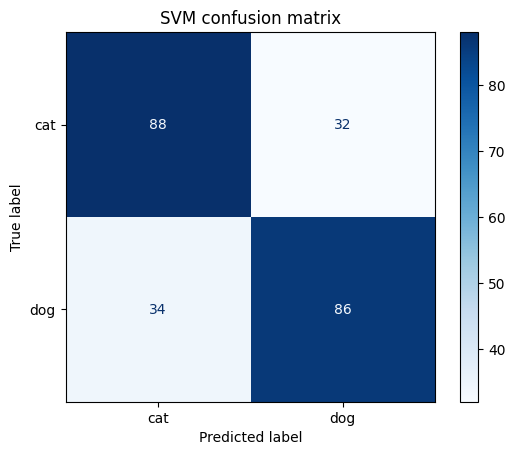

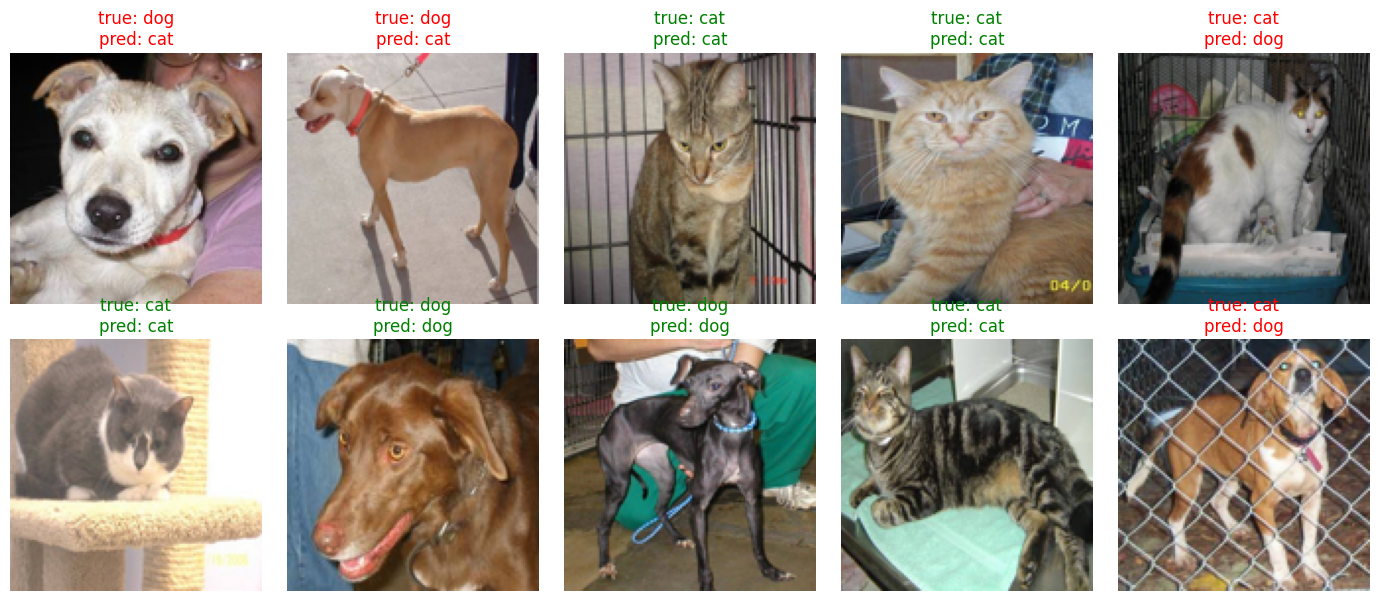

Saved model.


In [1]:
import os, glob, zipfile, random
import numpy as np
import joblib
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from skimage.feature import hog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

# ---------- Config ----------
IMG_SIZE = 64
N_PER_CLASS = 5000
SEED = 42
random.seed(SEED)

# ---------- 1. Unzip any zip files ----------
for z in glob.glob("/kaggle/input/**/*.zip", recursive=True):
    with zipfile.ZipFile(z) as zf:
        zf.extractall("/kaggle/working/data")

# ---------- 2. Collect labeled images (skip duplicate copies) ----------
exts = (".jpg", ".jpeg", ".png")
cats, dogs, seen = [], [], set()
for base in ["/kaggle/input", "/kaggle/working/data"]:
    for root, _, fs in os.walk(base):
        for f in fs:
            if not f.lower().endswith(exts) or f in seen:
                continue
            name, folder = f.lower(), os.path.basename(root).lower()
            if name.startswith("cat") or "cat" in folder:
                cats.append(os.path.join(root, f)); seen.add(f)
            elif name.startswith("dog") or "dog" in folder:
                dogs.append(os.path.join(root, f)); seen.add(f)

print(f"Found {len(cats)} cats and {len(dogs)} dogs")
assert cats and dogs, "No labeled images found. Check the dataset is added under Input."

random.shuffle(cats); random.shuffle(dogs)
n = min(N_PER_CLASS, len(cats), len(dogs))
files = cats[:n] + dogs[:n]
labels = np.array([0] * n + [1] * n)
print(f"Using {len(files)} images ({n} per class)")

# ---------- 3. HOG feature extraction ----------
def extract(path):
    try:
        img = Image.open(path)
        img.draft("RGB", (IMG_SIZE * 2, IMG_SIZE * 2))
        img = img.convert("L").resize((IMG_SIZE, IMG_SIZE))
        return hog(np.asarray(img), orientations=9,
                   pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    except Exception:
        return None

feats = [extract(f) for f in tqdm(files)]
keep = [i for i, f in enumerate(feats) if f is not None]
X = np.array([feats[i] for i in keep])
y = labels[keep]
paths_kept = [files[i] for i in keep]
print("Feature matrix:", X.shape)

# ---------- 4. Split ----------
idx = np.arange(len(y))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test, y_train, y_test = X[tr_idx], X[te_idx], y[tr_idx], y[te_idx]

# ---------- 5. Tune and train SVM ----------
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grid = GridSearchCV(
    pipe,
    {"svc__C": [1, 5, 10, 50], "svc__gamma": ["scale", 0.001, 0.0005]},
    cv=3, n_jobs=1, verbose=1,
)
grid.fit(X_train, y_train)
model = grid.best_estimator_
print("Best params:", grid.best_params_)

# ---------- 6. Evaluate the FINAL model ----------
preds = model.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds, target_names=["cat", "dog"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, preds, display_labels=["cat", "dog"], cmap="Blues")
plt.title("SVM confusion matrix")
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150)
plt.show()

# ---------- 7. Sample predictions ----------
names = ["cat", "dog"]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, j in zip(axes.ravel(), te_idx[:10]):
    ax.imshow(Image.open(paths_kept[j]).convert("RGB").resize((128, 128)))
    p = model.predict(X[j].reshape(1, -1))[0]
    ax.set_title(f"true: {names[y[j]]}\npred: {names[p]}",
                 color="green" if p == y[j] else "red")
    ax.axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/sample_predictions.png", dpi=150)
plt.show()

# ---------- 8. Save ----------
joblib.dump(model, "/kaggle/working/svm_cats_dogs.joblib")
print("Saved model.")